# Objetivo — detectar valores anômalos

**Pergunta:** no momento de um lançamento, o valor bruto é atípico em relação ao histórico disponível daquele parceiro e tipo de transação?

**Unidade:** uma transação. **Alvo de avaliação:** `flag_anomalia`, que indica uma distorção artificial do valor. Não é um rótulo de fraude, cancelamento ou inadimplência. O diagnóstico de rótulos abaixo usa apenas 2024.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)


## O que o gerador simula

O gerador seleciona aproximadamente 6% das transações de cada parceiro (arredondamento para cima). Entre elas, cerca de 70% recebem multiplicadores entre 1,5 e 3,5 e cerca de 30% entre 0,2 e 0,6. Valores normais variam e parceiros podem ter tendências crescentes ou decrescentes. A taxa não é imposta exatamente por mês.

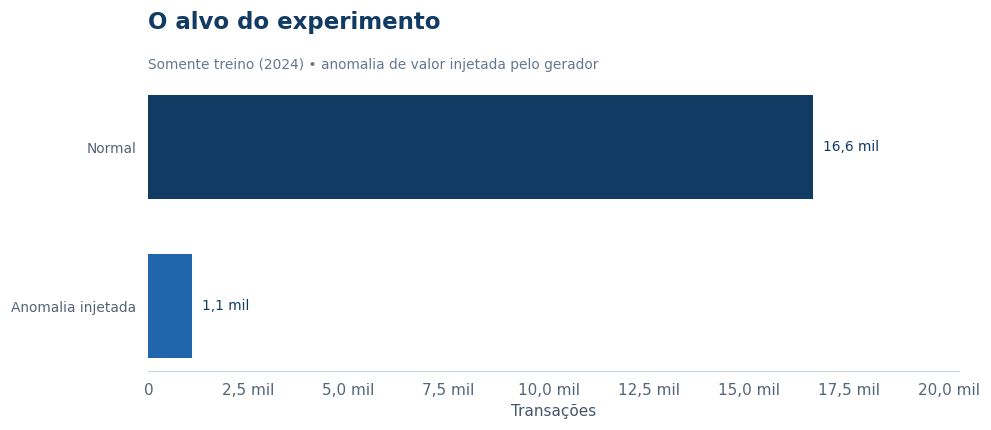

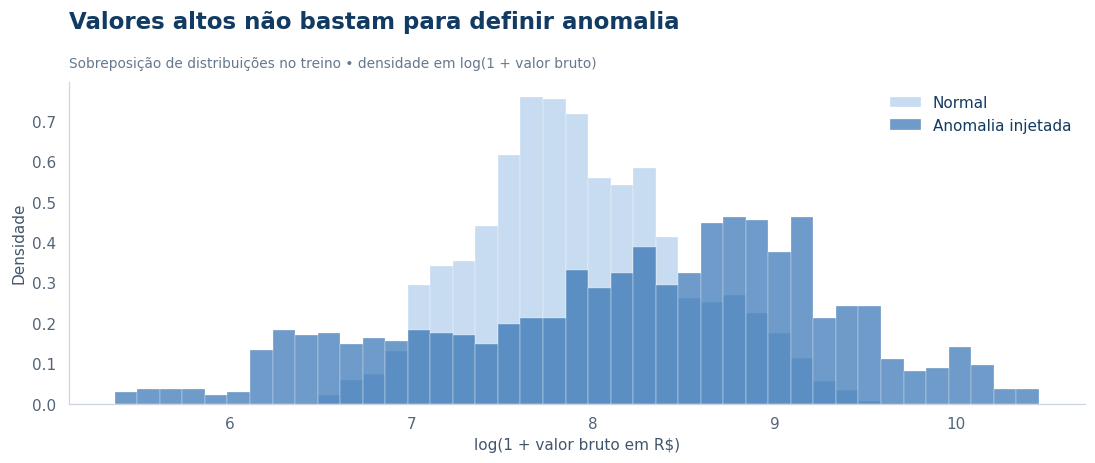

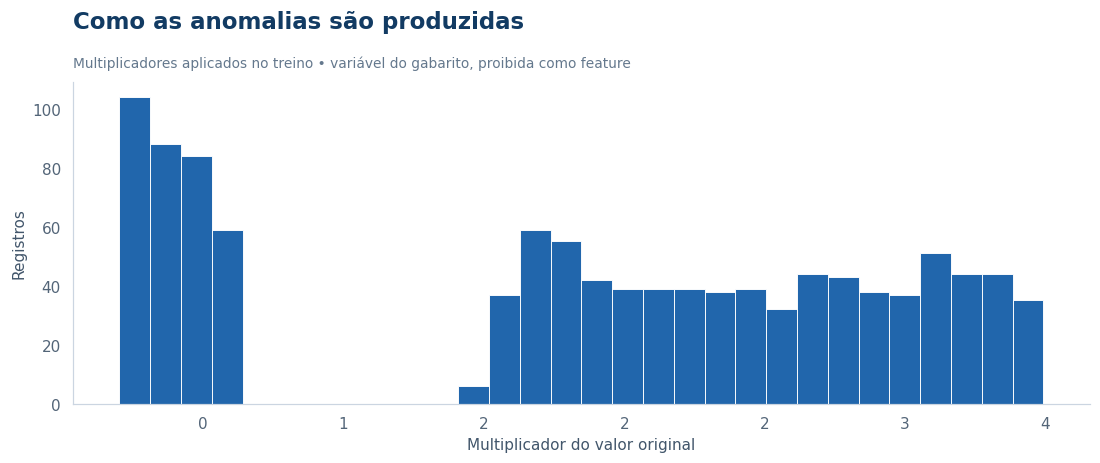

In [2]:
from ml.diagnostics import problem_figures
transactions = load_tables()["fact_transacoes_financeiras"]
figures, shortcut_audit = problem_figures(transactions)
for i, figure in enumerate(figures, 1):
    save_figure(figure, f"problema_{i:02d}", "experimento")
    display(figure)
    plt.close(figure)


## Possíveis atalhos e limitações

Na injeção, o valor bruto muda, mas o desconto absoluto original é preservado. A porcentagem de desconto pode denunciar a regra sintética. Por isso, `valor_liquido`, desconto e razão líquido/bruto ficam fora da matriz principal. A tabela abaixo diagnostica esse risco, usando só o treino.

In [3]:
display(style_table(shortcut_audit.round(3)))

classe,min,median,max
Anomalia,0.000000,0.000000,19.669000
Normal,0.000000,0.000000,4.999000


## Protocolo escolhido

- Treino não supervisionado em 2024, sem consultar o gabarito para remover anomalias.
- Validação no primeiro semestre de 2025: escolher modelo por AP e limiar por F1.
- Teste final no segundo semestre de 2025: avaliação sem novos ajustes.
- Atualizar apenas o contexto com transações de dias anteriores; pesos dos modelos e pré-processamento ficam congelados.
- Comparar baseline histórico, Isolation Forest e autoencoder.
- Excluir status, liquidações, saldos, rating/prazo agregado, IDs técnicos e todas as colunas do gabarito.

**Critério de sucesso:** superar referências simples e examinar precisão, recall, F1, AP, volume de alertas e erros. Sem custos operacionais definidos, o limiar F1 é uma escolha experimental, não um limiar de produção.

## Fontes

[Isolation Forest](https://scikit-learn.org/1.3/modules/generated/sklearn.ensemble.IsolationForest.html) · [Rede MLP](https://scikit-learn.org/1.3/modules/generated/sklearn.neural_network.MLPRegressor.html) · [Average Precision](https://scikit-learn.org/1.3/modules/generated/sklearn.metrics.average_precision_score.html).